In [ ]:
#1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving loan_approval_dataset.csv to loan_approval_dataset.csv


In [ ]:
df = pd.read_csv("loan_approval_dataset.csv")


In [ ]:
#3. First Look at Dataset
print(df.head())

   loan_id   no_of_dependents      education  self_employed   income_annum  \
0        1                  2       Graduate             No        9600000   
1        2                  0   Not Graduate            Yes        4100000   
2        3                  3       Graduate             No        9100000   
3        4                  3       Graduate             No        8200000   
4        5                  5   Not Graduate            Yes        9800000   

    loan_amount   loan_term   cibil_score   residential_assets_value  \
0      29900000          12           778                    2400000   
1      12200000           8           417                    2700000   
2      29700000          20           506                    7100000   
3      30700000           8           467                   18200000   
4      24200000          20           382                   12400000   

    commercial_assets_value   luxury_assets_value   bank_asset_value  \
0                  1760000

In [ ]:
print(df.shape)

(4269, 13)


In [ ]:
print(df.columns)

Index(['loan_id', ' no_of_dependents', ' education', ' self_employed',
       ' income_annum', ' loan_amount', ' loan_term', ' cibil_score',
       ' residential_assets_value', ' commercial_assets_value',
       ' luxury_assets_value', ' bank_asset_value', ' loan_status'],
      dtype='object')


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1    no_of_dependents          4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB
None


In [ ]:
print(df.isnull().sum())

loan_id                      0
 no_of_dependents            0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_score                 0
 residential_assets_value    0
 commercial_assets_value     0
 luxury_assets_value         0
 bank_asset_value            0
 loan_status                 0
dtype: int64


In [ ]:
#4. Remove Extra Spaces from Column Names
df.columns = df.columns.str.strip()

In [ ]:
print(df.columns)

Index(['loan_id', 'no_of_dependents', 'education', 'self_employed',
       'income_annum', 'loan_amount', 'loan_term', 'cibil_score',
       'residential_assets_value', 'commercial_assets_value',
       'luxury_assets_value', 'bank_asset_value', 'loan_status'],
      dtype='object')


In [ ]:
#5. Check Loan Status
print(df["loan_status"].value_counts())

loan_status
Approved    2656
Rejected    1613
Name: count, dtype: int64


In [ ]:
#now converted to the numerical form
df["loan_status"] = df["loan_status"].str.strip().str.lower()

df["loan_status"] = df["loan_status"].map({
    "approved": 1,
    "rejected": 0
})

In [ ]:
print(df["loan_status"].value_counts())

loan_status
1    2656
0    1613
Name: count, dtype: int64


In [ ]:
#7. Convert Categorical Columns
#education and self_employed can be a text values.
# machine learning model needs a numerical values

df["education"] = df["education"].str.strip().str.lower()
df["self_employed"] = df["self_employed"].str.strip().str.lower()

In [ ]:
df["education"] = df["education"].map({
    "graduate": 1,
    "not graduate": 0
})

In [ ]:
df["self_employed"] = df["self_employed"].map({
    "yes": 1,
    "no": 0
})

In [ ]:
#8. Create X and y
X = df[
    [
        "no_of_dependents",
        "education",
        "self_employed",
        "income_annum",
        "loan_amount",
        "loan_term",
        "cibil_score",
        "residential_assets_value",
        "commercial_assets_value"
    ]
]
y = df["loan_status"]

In [ ]:
#9. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [ ]:
#11. Create Logistic Regression Model
model = LogisticRegression(max_iter=1000)

In [ ]:
#Train:
#now model learn the relationship from the training data
model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [ ]:
#12. Check Model Coefficients
print("Intercept:", model.intercept_)

Intercept: [1.72656246]


In [ ]:
print("Coefficients:", model.coef_)

Coefficients: [[-0.07647684  0.06825858  0.01896553 -1.31685513  1.31881724 -0.85593898
   4.08631531  0.03154945  0.0928705 ]]


In [ ]:
#Better readable form:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

print(coefficients)

                    Feature  Coefficient
0          no_of_dependents    -0.076477
1                 education     0.068259
2             self_employed     0.018966
3              income_annum    -1.316855
4               loan_amount     1.318817
5                 loan_term    -0.855939
6               cibil_score     4.086315
7  residential_assets_value     0.031549
8   commercial_assets_value     0.092870


In [ ]:
#14. Make Predictions
y_pred = model.predict(X_test_scaled)

In [ ]:
print(y_pred)

[1 0 1 1 1 1 1 0 1 0 0 0 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 0 1 1 0 1 1
 0 1 0 0 1 0 1 1 1 1 0 0 1 1 1 1 1 0 0 1 0 1 1 1 1 0 1 0 1 1 0 1 1 1 0 1 1
 1 0 1 1 1 1 0 1 1 0 1 1 0 0 1 0 1 1 1 1 0 0 0 1 0 1 1 0 1 1 1 0 1 0 1 1 0
 0 0 1 1 0 0 1 0 0 1 1 1 1 0 0 0 0 1 1 1 1 1 0 1 1 1 1 0 1 1 1 0 0 1 1 1 1
 0 1 1 1 1 0 1 1 0 1 0 1 0 1 0 1 1 1 0 1 1 1 0 1 1 1 1 1 1 0 1 0 1 1 1 1 1
 1 1 0 1 0 1 0 0 0 1 1 0 0 1 1 0 0 0 1 0 1 1 0 1 0 0 0 1 1 1 1 0 0 1 1 0 1
 1 1 0 1 0 1 1 1 0 1 1 1 0 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1 1 0 0 1 0 1 0 1
 0 0 1 1 0 1 0 0 1 0 1 1 0 1 1 0 1 1 1 1 1 1 0 0 0 0 1 1 0 1 1 1 1 0 1 0 0
 0 0 1 1 1 0 0 0 1 1 0 1 1 0 0 1 1 1 1 1 1 1 0 1 1 1 1 0 1 0 0 1 1 1 1 1 0
 0 0 1 1 1 1 1 1 1 0 0 0 0 1 0 1 1 0 1 1 1 1 0 1 1 1 1 0 1 1 1 0 1 1 1 1 1
 1 0 0 0 1 1 1 1 1 1 1 1 0 0 0 1 1 0 1 1 0 1 1 1 1 1 1 0 1 0 1 1 1 1 0 1 0
 1 0 1 1 1 1 1 0 1 1 0 1 1 0 0 1 1 1 1 1 1 0 1 1 1 0 1 1 1 1 1 0 1 0 0 1 1
 1 1 1 1 1 0 1 0 1 1 1 0 0 1 1 1 1 1 1 1 0 0 1 0 1 0 1 1 0 0 0 1 0 0 1 0 1
 1 1 1 1 1 0 0 1 0 0 1 0 

In [ ]:
#15. Get Approval Probability
y_probability = model.predict_proba(X_test_scaled)
y_probability

'''
you got 2 columns:

Column 0 → Probability of Rejected
Column 1 → Probability of Approved
'''

'\nyou got 2 columns:\n\nColumn 0 → Probability of Rejected\nColumn 1 → Probability of Approved\n'

In [ ]:
#so
approved_probability = model.predict_proba(X_test_scaled)[:, 1]

In [ ]:
#16. Create Prediction Table
results = pd.DataFrame({
    "Actual Status": y_test.values,
    "Predicted Status": y_pred,
    "Approval Probability": approved_probability
})

print(results.head(10))

   Actual Status  Predicted Status  Approval Probability
0              0                 1              0.992775
1              0                 0              0.015980
2              0                 1              0.627945
3              1                 1              0.982487
4              1                 1              0.977589
5              1                 1              0.999351
6              1                 1              0.998246
7              0                 0              0.380541
8              1                 1              0.842909
9              0                 0              0.078427


In [ ]:
#For percentage:
results["Approval Probability (%)"] = (
    results["Approval Probability"] * 100
)

print(results.head(10))

   Actual Status  Predicted Status  Approval Probability  \
0              0                 1              0.992775   
1              0                 0              0.015980   
2              0                 1              0.627945   
3              1                 1              0.982487   
4              1                 1              0.977589   
5              1                 1              0.999351   
6              1                 1              0.998246   
7              0                 0              0.380541   
8              1                 1              0.842909   
9              0                 0              0.078427   

   Approval Probability (%)  
0                 99.277490  
1                  1.597967  
2                 62.794471  
3                 98.248748  
4                 97.758901  
5                 99.935090  
6                 99.824639  
7                 38.054063  
8                 84.290913  
9                  7.842687  


In [ ]:
#17. Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

Accuracy: 0.914519906323185
Accuracy (%): 91.4519906323185


In [ ]:
#18. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[278  45]
 [ 28 503]]


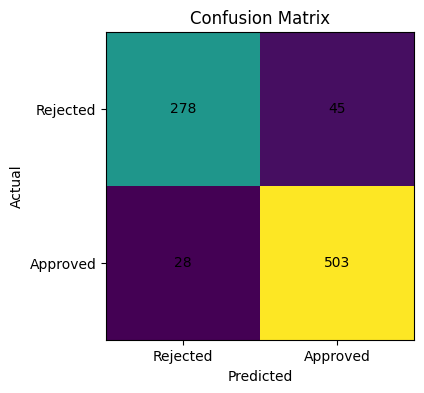

In [ ]:
#Visualize:
plt.figure(figsize=(6, 4))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["Rejected", "Approved"])
plt.yticks([0, 1], ["Rejected", "Approved"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j],
                 ha="center",
                 va="center")

plt.show()

In [ ]:
#19. Classification Report
print(classification_report(
    y_test,
    y_pred,
    target_names=["Rejected", "Approved"]
))

              precision    recall  f1-score   support

    Rejected       0.91      0.86      0.88       323
    Approved       0.92      0.95      0.93       531

    accuracy                           0.91       854
   macro avg       0.91      0.90      0.91       854
weighted avg       0.91      0.91      0.91       854



In [ ]:

new_applicant = pd.DataFrame({
    "no_of_dependents": [2],
    "education": [1],
    "self_employed": [0],
    "income_annum": [8000000],
    "loan_amount": [2000000],
    "loan_term": [10],
    "cibil_score": [750],
    "residential_assets_value": [5000000],
    "commercial_assets_value": [2000000]
})

In [ ]:
#Scale it:
new_applicant_scaled = scaler.transform(new_applicant)

In [ ]:
#Prediction:
prediction = model.predict(new_applicant_scaled)

In [ ]:
#Probability:
probability = model.predict_proba(
    new_applicant_scaled
)[0][1]

In [ ]:
#Print:
print("Approval Probability:", probability * 100)

Approval Probability: 88.99883473775735


In [ ]:
#Decision:
if probability >= 0.5:
    print("Loan Status: Approved")
else:
    print("Loan Status: Rejected")

Loan Status: Approved


In [ ]:
#21. Complete Final Prediction Block
prediction = model.predict(new_applicant_scaled)[0]

probability = model.predict_proba(
    new_applicant_scaled
)[0][1]

print("Loan Approval Probability:",
      round(probability * 100, 2), "%")

if prediction == 1:
    print("Prediction: Loan Approved")
else:
    print("Prediction: Loan Rejected")

Loan Approval Probability: 89.0 %
Prediction: Loan Approved


In [ ]:
#Complete Flow

'''
Loan Dataset
     ↓
Data Cleaning
     ↓
Categorical Encoding
     ↓
Select Features
     ↓
X and y
     ↓
Train-Test Split
     ↓
Feature Scaling
     ↓
Logistic Regression
     ↓
Model learns coefficients
     ↓
Linear Equation
     ↓
z = b0 + b1X1 + b2X2 + ... + b9X9
     ↓
Sigmoid Function
     ↓
Probability
     ↓
Threshold 0.5
     ↓
Approved / Rejected
     ↓
Accuracy + Confusion Matrix